<a href="https://colab.research.google.com/github/pichoendo/Laravel-Tests-General-Free/blob/main/FinalProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Visualisasi Data Rata-rata Pembelanjaan Konsumen Di Pusat Perbelanjaan Kota Istanbul turki Berdasarkan Gender dan Metode Pembayaran


# Importing & Mounting Library

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


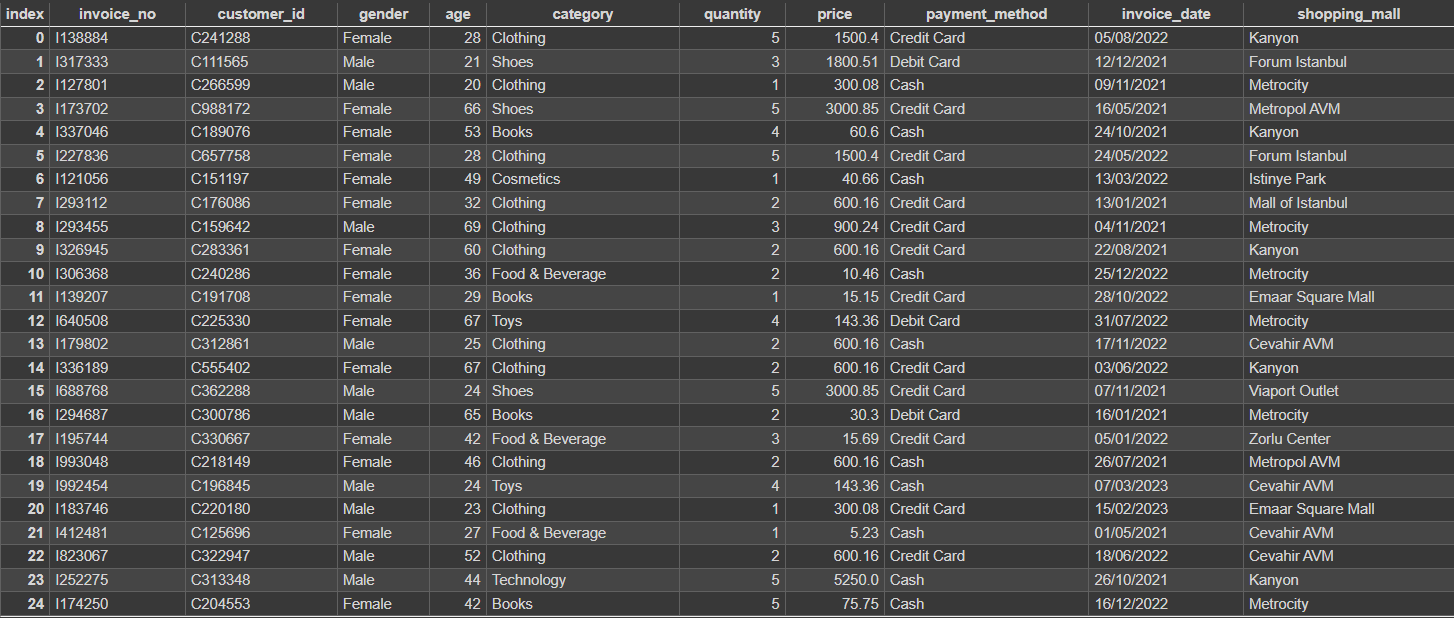

# Pengolahan data

Pembentukan dataframe dilakukan dengan hanya mengambil beberapa kolom saja dengan menggunakan parameter usecols.

Pada kolom **invoice_date** perlu dilakukan penyesuaian format dari string menjadi date time menggunakan ***parse_date*** dan ***dayFirst*** sebagai parameter bahwa format tanggal diawali dengan hari.

Pada kolom inovice_date di konversi sebagai tahun menggunakan dt.strftime('%Y')

Membentuk dataframe baru dengan mengelompokan data berdasarkan ***invoice_date, gender, payment_method*** lalu mengambil nilai rata rata menggunakan **mean()**

Terakhir melakukan reshape dengan unstack row dari kolom ***payment_method*** menjadi Colomn

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/dataset/data.csv', usecols=[
                 "gender", 'invoice_date', 'price', 'payment_method'], parse_dates=['invoice_date'], dayfirst=True)
df['invoice_date'] = df['invoice_date'].dt.strftime('%Y')
df = df.groupby(['invoice_date', 'gender', 'payment_method']).mean()
df

price
invoice_date gender payment_method            
2021         Female Cash            703.892563
                    Credit Card     682.131605
                    Debit Card      663.959294
             Male   Cash            690.004009
                    Credit Card     700.511948
                    Debit Card      700.789571
2022         Female Cash            675.581530
                    Credit Card     687.297689
                    Debit Card      696.862877
             Male   Cash            682.613067
                    Credit Card     693.124532
                    Debit Card      687.107631
2023         Female Cash            674.543784
                    Credit Card     635.304681
                    Debit Card      690.169198
             Male   Cash            713.802941
                    Credit Card     732.930860
                    Debit Card      673.416129

In [ ]:
df = df.unstack('payment_method')
df

price                        
payment_method             Cash Credit Card  Debit Card
invoice_date gender                                    
2021         Female  703.892563  682.131605  663.959294
             Male    690.004009  700.511948  700.789571
2022         Female  675.581530  687.297689  696.862877
             Male    682.613067  693.124532  687.107631
2023         Female  674.543784  635.304681  690.169198
             Male    713.802941  732.930860  673.416129

# Visualisasi Data

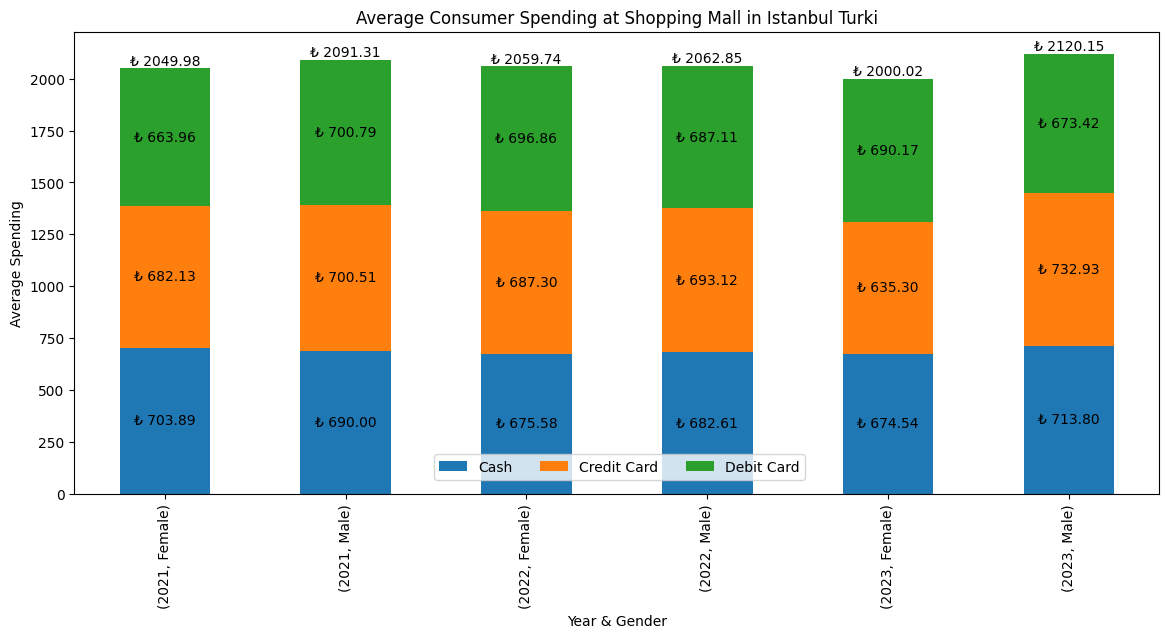

In [ ]:
element = df.plot.bar(stacked=True,figsize=(14,6))

for bars in element.containers:
    labels = [f"₺ {bar.get_height():.2f}"  for bar in bars]
    element.bar_label(bars, labels=labels, label_type='center')

element.bar_label(element.containers[-1], fmt='₺ %.2F')
element.set_xlabel('Year & Gender')
element.set_ylabel('Average Spending')
element.set_title('Average Consumer Spending at Shopping Mall in Istanbul Turki')
plt.legend(["Cash", "Credit Card",'Debit Card'], ncol=3, bbox_to_anchor = (0.68,0.1))
plt.show()